# Phase 2 results: zero-shot and five-shot prompting

Reviews the output of `scripts/run_prompting.py` for one split (dev by default):

1. sanity checks (are all runs there and complete?)
2. main comparison table
3. five-shot gains and cross-lingual gaps
4. output-format reliability (malformed rate etc.)
5. per-emotion F1
6. label cardinality and empty predictions
7. paired bootstrap confidence intervals: which differences are real?
8. example errors
9. wording sensitivity (if `--sensitivity` was run)

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SPLIT = "dev"          
ID_KEY = "alignment_id"
LABELS = ["anger", "anticipation", "disgust", "fear", "joy", "sadness", "surprise", "trust"]

PRED_DIR = PROJECT_ROOT / "outputs" / "predictions" / "prompting" / SPLIT
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics" / "prompting" / SPLIT
pd.set_option("display.precision", 3)

## 1. Sanity checks
Expect 8 rows (2 models × 2 languages × 2 conditions), the full dev size in `n` (not 20 from the smoke test), and the same prompt fingerprint everywhere.

In [2]:
summary = pd.read_csv(METRICS_DIR / "summary.csv")
summary = summary[summary["variant"] == "default"]
print(f"{len(summary)} runs")
display(summary[["model", "role", "lang", "condition", "n"]])

fingerprints = {json.loads(p.read_text())["fingerprint"] for p in METRICS_DIR.glob("*__default.json")}
print("prompt fingerprints:", fingerprints)   # should be exactly one
assert len(summary) == 8, "missing runs: check the job logs"
assert summary["n"].min() > 20, "this looks like the smoke-test summary, not the full run"

8 runs


,model,role,lang,condition,n
0,Qwen2.5-3B-Instruct,primary,en,zero_shot,497
1,Qwen2.5-3B-Instruct,primary,en,five_shot,497
2,Qwen2.5-3B-Instruct,primary,sv,zero_shot,497
3,Qwen2.5-3B-Instruct,primary,sv,five_shot,497
4,EuroLLM-9B-Instruct,second,en,zero_shot,497
5,EuroLLM-9B-Instruct,second,en,five_shot,497
6,EuroLLM-9B-Instruct,second,sv,zero_shot,497
7,EuroLLM-9B-Instruct,second,sv,five_shot,497


prompt fingerprints: {'091255db13ac2d57'}


## 2. Main results table

In [3]:
main_cols = ["macro_f1", "micro_f1", "samples_f1", "jaccard", "exact_match"]
main = summary.pivot_table(index=["model", "lang"], columns="condition", values=main_cols)
main = main.reindex(columns=["zero_shot", "five_shot"], level=1)
main

exact_match             jaccard            macro_f1  \
condition                  zero_shot five_shot zero_shot five_shot zero_shot   
model               lang                                                       
EuroLLM-9B-Instruct en         0.233     0.217     0.357     0.360     0.365   
                    sv         0.197     0.229     0.296     0.360     0.302   
Qwen2.5-3B-Instruct en         0.187     0.195     0.271     0.305     0.302   
                    sv         0.141     0.177     0.200     0.266     0.210   

                                    micro_f1           samples_f1            
condition                five_shot zero_shot five_shot  zero_shot five_shot  
model               lang                                                     
EuroLLM-9B-Instruct en       0.392     0.399     0.419      0.402     0.414  
                    sv       0.387     0.343     0.410      0.333     0.409  
Qwen2.5-3B-Instruct en       0.356     0.331     0.365      0.303     0.345  
                    sv       0.296     0.242     0.310      0.223     0.299

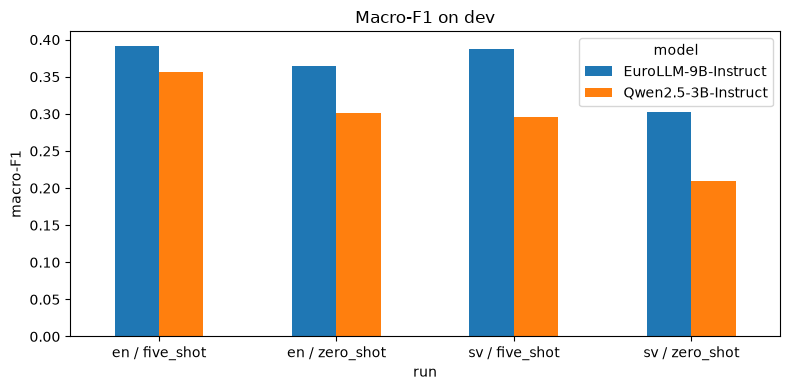

In [4]:
ax = (summary.assign(run=summary["lang"] + " / " + summary["condition"])
             .pivot(index="run", columns="model", values="macro_f1")
             .plot.bar(figsize=(8, 4), rot=0))
ax.set_ylabel("macro-F1"); ax.set_title(f"Macro-F1 on {SPLIT}"); ax.set_ylim(0, None)
plt.tight_layout(); plt.show()

## 3. Five-shot gain and cross-lingual gap
Positive five-shot gain = demonstrations help. Positive EN−SV gap = the model is worse on Swedish.

In [5]:
m = summary.set_index(["model", "lang", "condition"])["macro_f1"].unstack("condition")
gain = (m["five_shot"] - m["zero_shot"]).unstack("lang").add_prefix("five_shot_gain_")

m2 = summary.set_index(["model", "condition", "lang"])["macro_f1"].unstack("lang")
langs = [c for c in m2.columns if c != "en"]
gap = m2["en"].sub(m2[langs[0]]).unstack("condition").add_prefix("en_minus_" + langs[0] + "_")

pd.concat([gain, gap], axis=1)

,five_shot_gain_en,five_shot_gain_sv,en_minus_sv_five_shot,en_minus_sv_zero_shot
model,,,,
EuroLLM-9B-Instruct,0.027,0.085,0.004,0.063
Qwen2.5-3B-Instruct,0.054,0.086,0.060,0.092


## 4. Output-format reliability
The spec asks for the malformed-output rate separately. `strict_json_rate` = whole output was exactly a JSON list; `wellformed_but_no_label_rate` = valid list but no permitted label (e.g. `[]`).

In [6]:
fmt_cols = ["malformed_rate", "strict_json_rate", "wellformed_but_no_label_rate", "empty_prediction_rate"]
summary.set_index(["model", "lang", "condition"])[fmt_cols]

malformed_rate  strict_json_rate  \
model               lang condition                                     
Qwen2.5-3B-Instruct en   zero_shot           0.002              0.99   
                         five_shot           0.000              1.00   
                    sv   zero_shot           0.000              1.00   
                         five_shot           0.000              1.00   
EuroLLM-9B-Instruct en   zero_shot           0.000              1.00   
                         five_shot           0.000              1.00   
                    sv   zero_shot           0.000              1.00   
                         five_shot           0.000              1.00   

                                    wellformed_but_no_label_rate  \
model               lang condition                                 
Qwen2.5-3B-Instruct en   zero_shot                         0.167   
                         five_shot                         0.078   
                    sv   zero_shot                         0.175   
                         five_shot                         0.048   
EuroLLM-9B-Instruct en   zero_shot                         0.006   
                         five_shot                         0.002   
                    sv   zero_shot                         0.000   
                         five_shot                         0.002   

                                    empty_prediction_rate  
model               lang condition                         
Qwen2.5-3B-Instruct en   zero_shot                  0.169  
                         five_shot                  0.078  
                    sv   zero_shot                  0.175  
                         five_shot                  0.048  
EuroLLM-9B-Instruct en   zero_shot                  0.006  
                         five_shot                  0.002  
                    sv   zero_shot                  0.000  
                         five_shot                  0.002

## 5. Per-emotion F1

In [7]:
def load_metrics(model, lang, condition, variant="default"):
    return json.loads((METRICS_DIR / f"{model}__{lang}__{condition}__{variant}.json").read_text())

per_label = {}
for _, r in summary.iterrows():
    met = load_metrics(r["model"], r["lang"], r["condition"])
    per_label[(r["model"], r["lang"], r["condition"])] = {l: met["per_label"][l]["f1"] for l in LABELS}
per_label_f1 = pd.DataFrame(per_label)
first = summary.iloc[0]
per_label_f1["gold_support"] = [load_metrics(first["model"], first["lang"], first["condition"])
                                ["per_label"][l]["support"] for l in LABELS]
per_label_f1

Qwen2.5-3B-Instruct                                \
                              en                  sv             
                       zero_shot five_shot zero_shot five_shot   
anger                      0.321     0.370     0.170     0.297   
anticipation               0.388     0.370     0.280     0.296   
disgust                    0.176     0.379     0.028     0.327   
fear                       0.209     0.253     0.053     0.148   
joy                        0.317     0.340     0.240     0.291   
sadness                    0.422     0.391     0.389     0.367   
surprise                   0.180     0.338     0.262     0.265   
trust                      0.400     0.408     0.258     0.380   

             EuroLLM-9B-Instruct                               gold_support  
                              en                  sv                         
                       zero_shot five_shot zero_shot five_shot               
anger                      0.531     0.540     0.509     0.484          125  
anticipation               0.398     0.471     0.213     0.487          119  
disgust                    0.268     0.400     0.257     0.365           67  
fear                       0.421     0.397     0.360     0.400           67  
joy                        0.553     0.512     0.437     0.468           77  
sadness                    0.319     0.323     0.342     0.418           89  
surprise                   0.347     0.366     0.278     0.298           84  
trust                      0.080     0.125     0.022     0.180           87

/tmp/ipykernel_2656598/3699079690.py:2: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  f1_only = per_label_f1.drop(columns="gold_support")


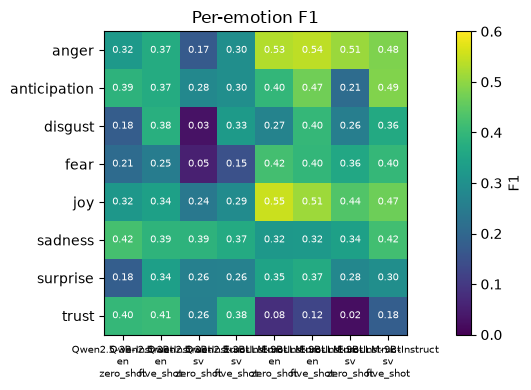

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
f1_only = per_label_f1.drop(columns="gold_support")
im = ax.imshow(f1_only.values, cmap="viridis", vmin=0, vmax=max(0.6, f1_only.values.max()))
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xticks(range(f1_only.shape[1]),
              ["\n".join(c) for c in f1_only.columns], fontsize=7)
for i in range(f1_only.shape[0]):
    for j in range(f1_only.shape[1]):
        ax.text(j, i, f"{f1_only.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
fig.colorbar(im, label="F1"); ax.set_title("Per-emotion F1"); plt.tight_layout(); plt.show()

## 6. Label cardinality, label distribution and empty predictions

In [9]:
def load_preds(model, lang, condition, variant="default"):
    path = PRED_DIR / f"{model}__{lang}__{condition}__{variant}.jsonl"
    return pd.DataFrame([json.loads(l) for l in path.open(encoding="utf-8")])

summary.set_index(["model", "lang", "condition"])[["gold_label_cardinality", "pred_label_cardinality"]]

gold_label_cardinality  \
model               lang condition                           
Qwen2.5-3B-Instruct en   zero_shot                   1.439   
                         five_shot                   1.439   
                    sv   zero_shot                   1.439   
                         five_shot                   1.439   
EuroLLM-9B-Instruct en   zero_shot                   1.439   
                         five_shot                   1.439   
                    sv   zero_shot                   1.439   
                         five_shot                   1.439   

                                    pred_label_cardinality  
model               lang condition                          
Qwen2.5-3B-Instruct en   zero_shot                   0.936  
                         five_shot                   1.050  
                    sv   zero_shot                   0.855  
                         five_shot                   1.052  
EuroLLM-9B-Instruct en   zero_shot                   1.181  
                         five_shot                   1.288  
                    sv   zero_shot                   1.193  
                         five_shot                   1.249

In [10]:
# How often is each emotion predicted, compared with how often it is gold?
rows = {}
for _, r in summary.iterrows():
    df = load_preds(r["model"], r["lang"], r["condition"])
    rows[(r["model"], r["lang"], r["condition"])] = pd.Series(
        [l for p in df["pred"] for l in p]).value_counts().reindex(LABELS, fill_value=0)
gold_counts = pd.Series([l for g in df["gold"] for l in g]).value_counts().reindex(LABELS, fill_value=0)
dist = pd.DataFrame(rows); dist.insert(0, "GOLD", gold_counts)
dist

GOLD Qwen2.5-3B-Instruct                                \
                                   en                  sv             
                            zero_shot five_shot zero_shot five_shot   
anger         125                  43        59        28        50   
anticipation  119                 144        81        81        84   
disgust        67                  24       107         4        80   
fear           67                  19        20         8        14   
joy            77                  24        23        23        40   
sadness        89                  91        49        91        69   
surprise       84                  27        64        99        52   
trust          87                  93       119        91       134   

             EuroLLM-9B-Instruct                                
                              en                  sv            
                       zero_shot five_shot zero_shot five_shot  
anger                        146       101       146        98  
anticipation                  87       187        22       152  
disgust                       82       113        73       103  
fear                          47        49        83        68  
joy                          122        83       161        94  
sadness                       30        35        28        45  
surprise                      60        47        74        37  
trust                         13        25         6        24

In [11]:
# Empty predictions: how many, and which gold emotions do those texts have?
for _, r in summary.iterrows():
    df = load_preds(r["model"], r["lang"], r["condition"])
    empty = df[df["pred"].str.len() == 0]
    counts = pd.Series([l for g in empty["gold"] for l in g]).value_counts().to_dict()
    print(f"{r['model']:28s} {r['lang']} {r['condition']:9s}: "
          f"{len(empty):4d}/{len(df)} empty | gold of those: {counts}")

Qwen2.5-3B-Instruct          en zero_shot:   84/497 empty | gold of those: {'anger': 21, 'anticipation': 20, 'trust': 17, 'surprise': 14, 'joy': 14, 'sadness': 13, 'fear': 8, 'disgust': 7}
Qwen2.5-3B-Instruct          en five_shot:   39/497 empty | gold of those: {'anticipation': 11, 'joy': 11, 'surprise': 9, 'trust': 6, 'anger': 6, 'disgust': 5, 'sadness': 4, 'fear': 1}
Qwen2.5-3B-Instruct          sv zero_shot:   87/497 empty | gold of those: {'anger': 23, 'anticipation': 20, 'trust': 17, 'sadness': 17, 'joy': 14, 'surprise': 12, 'disgust': 9, 'fear': 7}
Qwen2.5-3B-Instruct          sv five_shot:   24/497 empty | gold of those: {'joy': 8, 'anger': 7, 'anticipation': 6, 'trust': 4, 'sadness': 3, 'surprise': 2, 'disgust': 1}
EuroLLM-9B-Instruct          en zero_shot:    3/497 empty | gold of those: {'trust': 1, 'fear': 1, 'anger': 1, 'disgust': 1, 'sadness': 1}
EuroLLM-9B-Instruct          en five_shot:    1/497 empty | gold of those: {'anger': 1, 'disgust': 1, 'sadness': 1}
EuroLLM-9B

## 7. Paired bootstrap: which differences are real?

Resamples the dev texts 1,000 times. For a comparison A vs B, the *same* resampled texts are
used for both (paired, matched by alignment ID), which removes the noise from which texts were sampled.
If the 95% interval of the difference excludes 0, the difference is unlikely to be noise.

In [12]:
def f1s(Y, P):
    tp = (Y & P).sum(0); fp = (~Y & P).sum(0); fn = (Y & ~P).sum(0)
    denom = 2 * tp + fp + fn
    per_label = np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)
    micro = 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)
    return per_label.mean(), micro

def binarise(label_lists):
    return np.array([[l in set(x) for l in LABELS] for x in label_lists], dtype=bool)

def run_arrays(model, lang, condition):
    df = load_preds(model, lang, condition).set_index(ID_KEY)
    return df, binarise(df["gold"]), binarise(df["pred"])

def paired_bootstrap(a, b, n_boot=1000, seed=0, metric=0):
    """a, b: (model, lang, condition). metric 0 = macro-F1, 1 = micro-F1.
    Returns observed difference b - a and its 95% CI."""
    da, _, _ = run_arrays(*a); db, _, _ = run_arrays(*b)
    ids = da.index.intersection(db.index)
    Ya, Pa = binarise(da.loc[ids, "gold"]), binarise(da.loc[ids, "pred"])
    Yb, Pb = binarise(db.loc[ids, "gold"]), binarise(db.loc[ids, "pred"])
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(ids), len(ids))
        diffs.append(f1s(Yb[idx], Pb[idx])[metric] - f1s(Ya[idx], Pa[idx])[metric])
    obs = f1s(Yb, Pb)[metric] - f1s(Ya, Pa)[metric]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return obs, lo, hi, len(ids)

models = summary["model"].unique(); langs = summary["lang"].unique()
comparisons = []
for mo in models:
    for la in langs:
        comparisons.append(("five vs zero", (mo, la, "zero_shot"), (mo, la, "five_shot")))
    for co in ["zero_shot", "five_shot"]:
        other = [l for l in langs if l != "en"][0]
        comparisons.append((f"{other} vs en", (mo, "en", co), (mo, other, co)))
if len(models) == 2:
    for la in langs:
        for co in ["zero_shot", "five_shot"]:
            comparisons.append((f"{models[1]} vs {models[0]}", (models[0], la, co), (models[1], la, co)))

rows = []
for name, a, b in comparisons:
    obs, lo, hi, n = paired_bootstrap(a, b)
    rows.append({"comparison": name, "A": " / ".join(a), "B": " / ".join(b), "n_paired": n,
                 "macro_f1_diff (B-A)": obs, "ci_low": lo, "ci_high": hi,
                 "significant": not (lo <= 0 <= hi)})
boot = pd.DataFrame(rows)
boot

,comparison,A,B,n_paired,macro_f1_diff (B-A),ci_low,ci_high,significant
0,five vs zero,Qwen2.5-3B-Instruct / en / zero_shot,Qwen2.5-3B-Instruct / en / five_shot,497,0.054,0.018,0.088,True
1,five vs zero,Qwen2.5-3B-Instruct / sv / zero_shot,Qwen2.5-3B-Instruct / sv / five_shot,497,0.086,0.052,0.121,True
2,sv vs en,Qwen2.5-3B-Instruct / en / zero_shot,Qwen2.5-3B-Instruct / sv / zero_shot,497,-0.092,-0.128,-0.054,True
3,sv vs en,Qwen2.5-3B-Instruct / en / five_shot,Qwen2.5-3B-Instruct / sv / five_shot,497,-0.060,-0.097,-0.021,True
4,five vs zero,EuroLLM-9B-Instruct / en / zero_shot,EuroLLM-9B-Instruct / en / five_shot,497,0.027,-0.006,0.062,False
5,five vs zero,EuroLLM-9B-Instruct / sv / zero_shot,EuroLLM-9B-Instruct / sv / five_shot,497,0.085,0.050,0.120,True
6,sv vs en,EuroLLM-9B-Instruct / en / zero_shot,EuroLLM-9B-Instruct / sv / zero_shot,497,-0.063,-0.102,-0.027,True
7,sv vs en,EuroLLM-9B-Instruct / en / five_shot,EuroLLM-9B-Instruct / sv / five_shot,497,-0.004,-0.039,0.030,False
8,EuroLLM-9B-Instruct vs Qwen2.5-3B-Instruct,Qwen2.5-3B-Instruct / en / zero_shot,EuroLLM-9B-Instruct / en / zero_shot,497,0.063,0.019,0.108,True
9,EuroLLM-9B-Instruct vs Qwen2.5-3B-Instruct,Qwen2.5-3B-Instruct / en / five_shot,EuroLLM-9B-Instruct / en / five_shot,497,0.036,-0.004,0.075,False


## 8. Example errors
Read a sample of wrong predictions; use these for the qualitative error analysis.

In [13]:
def show_errors(model, lang, condition, k=10, seed=0):
    df = load_preds(model, lang, condition)
    wrong = df[df["gold"].apply(set) != df["pred"].apply(set)]
    print(f"{len(wrong)}/{len(df)} not exactly right")
    with pd.option_context("display.max_colwidth", 120):
        display(wrong.sample(min(k, len(wrong)), random_state=seed)[["text", "gold", "pred", "raw_output"]])

r0 = summary.iloc[0]
show_errors(r0["model"], [l for l in langs if l != "en"][0], "five_shot")

409/497 not exactly right


,text,gold,pred,raw_output
279,"Jag vet allt om dig, ända sen din första match mot Apollo Creed.",[disgust],[trust],"[""trust""]"
359,Det är till Mr Blair.,"[anger, anticipation]",[trust],"[""trust""]"
361,Vad bad han dig att berätta?,"[anger, anticipation]",[anticipation],"[""anticipation""]"
426,"- Hej, hittade du honom?",[anticipation],[surprise],"[""surprise""]"
123,Vad är det för svagt med att vilja ha?,[surprise],[disgust],"[""disgust""]"
483,Jag älskar Erik Bauer.,"[joy, trust]",[joy],"[""joy""]"
266,Nu har jag lärt mig en läxa.,[trust],[],[]
363,En mycket intellektuell 16-åring.,[joy],[],[]
77,- Du kan aldrig gissa var vi har varit.,"[anticipation, surprise]",[anticipation],"[""anticipation""]"
269,Jag tror detta är ett bra ställe att börja leta på.,[anticipation],[trust],"[""trust""]"


## 9. Wording sensitivity (dev only)
Only runs if `scripts/run_prompting.py --split dev --sensitivity` has finished.

In [14]:
sens_path = METRICS_DIR / "summary_sensitivity.csv"
if sens_path.exists():
    sens = pd.read_csv(sens_path)
    table = sens.pivot_table(index=["model", "lang", "condition"], columns="variant", values="macro_f1")
    table["range"] = table.max(axis=1) - table.min(axis=1)
    table["std"] = table.drop(columns="range").std(axis=1)
    display(table)
    display(sens.pivot_table(index=["model", "lang", "condition"], columns="variant", values="malformed_rate"))
else:
    print("No sensitivity results yet: sbatch jobs/run_prompting.sh dev --sensitivity")

No sensitivity results yet: sbatch jobs/run_prompting.sh dev --sensitivity
